# Projet Deep Learning : détection des maladies de la tomate par CNN
Fossé laboratoire (PlantVillage) / terrain (PlantDoc).

Ordre d'exécution : tout lancer de haut en bas (Exécution > Tout exécuter). GPU recommandé (Colab : Exécution > Modifier le type d'exécution).
Si vous êtes sur Kaggle : ajoutez les deux jeux avec "Add Data" et adaptez PV_ROOT / PD_TRAIN / PD_TEST dans la cellule 3.

## 0. Configuration

In [1]:
import os, glob, random, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import rgb_to_hsv
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             recall_score, precision_score, accuracy_score)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
IMG = 64            # taille des images (64x64) : suffisant et rapide
CULTURE = "tomato"  # culture ciblée (présente dans PlantVillage ET PlantDoc)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Téléchargement des données (script reproductible)
Les deux jeux sont clonés depuis GitHub (pas de compte nécessaire). Pour PlantVillage, seules les images de tomate sont récupérées.

In [2]:
# PlantDoc (split train/test officiel)
if not os.path.exists("PlantDoc-Dataset"):
    !git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git

# PlantVillage (miroir GitHub), tomate uniquement
if not os.path.exists("PlantVillage-Dataset"):
    !git clone --depth 1 --filter=blob:none --sparse https://github.com/spMohanty/PlantVillage-Dataset.git
    %cd PlantVillage-Dataset
    !git sparse-checkout set --no-cone "raw/color/Tomato*"
    %cd ..

!ls PlantVillage-Dataset/raw/color
!ls PlantDoc-Dataset/train | head -50

Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 28.48 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.
Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 206, done.
remote: Counting objects: 100% (206/206), done.
remote: Compressing objects: 100% (169/169), done.
remote: Total 206 (delta 37), reused 204 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (206/206), 7.47 MiB | 24.61 MiB/s, done.
Resolving deltas: 100% (37/37), done.
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 9 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 255.05 KiB | 

## 2. Exploration : classes communes et déséquilibre
Les noms de classes diffèrent entre les deux jeux. La fonction `to_common` les ramène à un vocabulaire commun.
La classe "Target spot" n'existe pas dans PlantDoc : elle est exclue pour garder des classes comparables.

PlantVillage : 16756 images, 16742 après dédoublonnage exact
Classes communes : ['bacterial_spot', 'early_blight', 'healthy', 'late_blight', 'leaf_mold', 'mosaic_virus', 'septoria', 'yellow_curl_virus']


,PlantVillage,PlantDoc train,PlantDoc test
bacterial_spot,2127,101,9
early_blight,1000,79,9
healthy,1585,55,8
late_blight,1901,101,10
leaf_mold,952,85,6
mosaic_virus,373,44,10
septoria,1771,140,11
yellow_curl_virus,5357,70,6


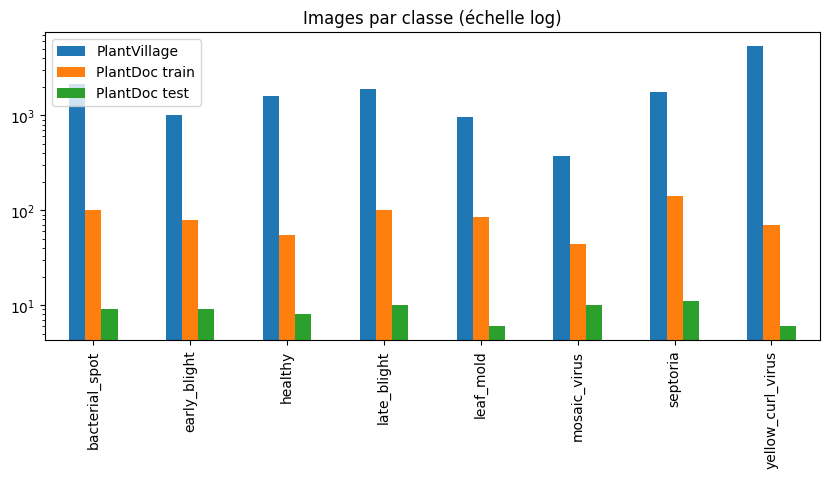

In [3]:
PV_ROOT  = "PlantVillage-Dataset/raw/color"
PD_TRAIN = "PlantDoc-Dataset/train"
PD_TEST  = "PlantDoc-Dataset/test"

def to_common(name):
    n = " ".join(name.lower().replace("_", " ").replace("-", " ").split())
    if "healthy" in n or n in ("tomato leaf", "tomato"): return "healthy"
    if "bacterial" in n:    return "bacterial_spot"
    if "early blight" in n: return "early_blight"
    if "late blight" in n:  return "late_blight"
    if "mold" in n:         return "leaf_mold"
    if "septoria" in n:     return "septoria"
    if "spider" in n or "mite" in n: return "spider_mites"
    if "yellow" in n:       return "yellow_curl_virus"
    if "mosaic" in n:       return "mosaic_virus"
    return None  # ex. target spot : absent de PlantDoc

def gather(root):
    items = []
    for dp, _, fn in os.walk(root):
        imgs = [f for f in fn if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        folder = os.path.basename(dp)
        if not imgs or CULTURE not in folder.lower(): continue
        lab = to_common(folder)
        if lab is None: continue
        items += [(os.path.join(dp, f), lab) for f in imgs]
    return items

def dedupe(items):
    # supprime les doublons exacts (même contenu) pour limiter les fuites de données
    seen, out = set(), []
    for p, l in items:
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        if h not in seen:
            seen.add(h); out.append((p, l))
    return out

pv_items = gather(PV_ROOT)
n0 = len(pv_items); pv_items = dedupe(pv_items)
print(f"PlantVillage : {n0} images, {len(pv_items)} après dédoublonnage exact")
pd_tr_items, pd_te_items = gather(PD_TRAIN), gather(PD_TEST)

common = sorted(set(l for _, l in pv_items) & set(l for _, l in pd_tr_items) & set(l for _, l in pd_te_items))
CLASSES = common
print("Classes communes :", CLASSES)
pv_items    = [x for x in pv_items if x[1] in CLASSES]
pd_tr_items = [x for x in pd_tr_items if x[1] in CLASSES]
pd_te_items = [x for x in pd_te_items if x[1] in CLASSES]

count = pd.DataFrame({
    "PlantVillage": pd.Series([l for _, l in pv_items]).value_counts(),
    "PlantDoc train": pd.Series([l for _, l in pd_tr_items]).value_counts(),
    "PlantDoc test": pd.Series([l for _, l in pd_te_items]).value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
display(count)
count.plot.bar(figsize=(10, 4), logy=True, title="Images par classe (échelle log)"); plt.show()

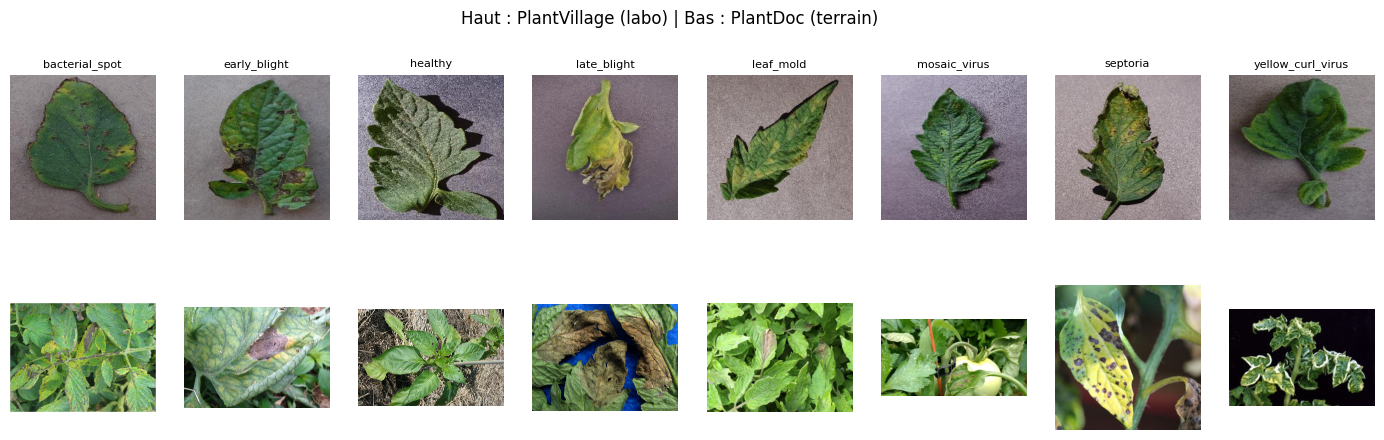

In [4]:
# Exemples d'images : labo (haut) vs terrain (bas)
fig, ax = plt.subplots(2, len(CLASSES), figsize=(2.2 * len(CLASSES), 5))
for j, c in enumerate(CLASSES):
    for i, items in enumerate([pv_items, pd_tr_items]):
        paths = [p for p, l in items if l == c]
        ax[i, j].imshow(Image.open(random.choice(paths)).convert("RGB")); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(c, fontsize=8)
plt.suptitle("Haut : PlantVillage (labo) | Bas : PlantDoc (terrain)"); plt.show()

## 3. Chargement et découpage sans fuite
- PlantVillage : découpage stratifié 70/15/15 (train/val/test). Limite : PlantVillage contient plusieurs photos d'une même feuille ; l'identifiant de la feuille n'étant pas disponible, un risque résiduel de fuite subsiste (à mentionner dans le rapport).
- PlantDoc : le test officiel n'est JAMAIS utilisé pour l'entraînement ni le choix des modèles. On sépare 20 % du train officiel en validation.

In [5]:
def load(path):
    try:
        return np.asarray(Image.open(path).convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
    except Exception:
        return None

def load_all(items):
    with ThreadPoolExecutor(8) as ex:
        arrs = list(ex.map(load, [p for p, _ in items]))
    keep = [i for i, a in enumerate(arrs) if a is not None]
    X = np.stack([arrs[i] for i in keep])
    y = np.array([CLASSES.index(items[i][1]) for i in keep])
    return X, y, [items[i][0] for i in keep]

X_pv, y_pv, _ = load_all(pv_items)
X_pdtr_all, y_pdtr_all, p_pdtr_all = load_all(pd_tr_items)
X_pdte, y_pdte, p_pdte = load_all(pd_te_items)

X_pv_tr, X_tmp, y_pv_tr, y_tmp = train_test_split(X_pv, y_pv, test_size=0.30, stratify=y_pv, random_state=SEED)
X_pv_va, X_pv_te, y_pv_va, y_pv_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
try:
    X_pd_tr, X_pd_va, y_pd_tr, y_pd_va = train_test_split(X_pdtr_all, y_pdtr_all, test_size=0.2, stratify=y_pdtr_all, random_state=SEED)
except ValueError:  # classes trop petites pour stratifier
    X_pd_tr, X_pd_va, y_pd_tr, y_pd_va = train_test_split(X_pdtr_all, y_pdtr_all, test_size=0.2, random_state=SEED)

print("PV  train/val/test :", len(X_pv_tr), len(X_pv_va), len(X_pv_te))
print("PD  train/val/test :", len(X_pd_tr), len(X_pd_va), len(X_pdte))
N = len(CLASSES)

PV  train/val/test : 10546 2260 2260
PD  train/val/test : 540 135 69


## 4. Outils : entraînement, métriques, graphiques

In [6]:
def make_ds(X, y=None, shuffle=False, bs=64):
    ds = tf.data.Dataset.from_tensor_slices((X, y) if y is not None else X)
    if shuffle: ds = ds.shuffle(min(len(X), 5000), seed=SEED)
    ds = ds.batch(bs)
    if y is not None: ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b))
    else:             ds = ds.map(lambda a: tf.cast(a, tf.float32))
    return ds.prefetch(tf.data.AUTOTUNE)

HIST, ROWS = {}, []

def fit(model, Xtr, ytr, Xva, yva, name, epochs=20, lr=1e-3, class_weight=True, patience=4):
    cw = None
    if class_weight:
        w = compute_class_weight("balanced", classes=np.arange(N), y=ytr)
        cw = {i: float(w[i]) for i in range(N)}
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    es = callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    h = model.fit(make_ds(Xtr, ytr, True), validation_data=make_ds(Xva, yva), epochs=epochs,
                  class_weight=cw, callbacks=[es], verbose=2)
    HIST[name] = h.history
    return model

def predict(model, X):
    return model.predict(make_ds(X), verbose=0).argmax(1)

HEALTHY = CLASSES.index("healthy") if "healthy" in CLASSES else None

def metrics(y, p):
    labs = list(range(N))
    m = dict(F1_macro=f1_score(y, p, labels=labs, average="macro", zero_division=0),
             Rappel_macro=recall_score(y, p, labels=labs, average="macro", zero_division=0),
             Precision_macro=precision_score(y, p, labels=labs, average="macro", zero_division=0),
             Accuracy=accuracy_score(y, p))
    if HEALTHY is not None:
        sick = y != HEALTHY
        m["Maladie_ratee"] = float(np.mean(p[sick] == HEALTHY))  # feuille malade classée saine
    return m

def evaluate(model, name):
    row = {"Modèle": name}
    for tag, X, y in [("PV", X_pv_te, y_pv_te), ("PD", X_pdte, y_pdte)]:
        for k, v in metrics(y, predict(model, X)).items(): row[f"{k}_{tag}"] = round(v, 3)
    ROWS.append(row)
    print(pd.DataFrame([row]).T)

def plot_history(names):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for n in names:
        ax[0].plot(HIST[n]["loss"], label=f"{n} train"); ax[0].plot(HIST[n]["val_loss"], "--", label=f"{n} val")
        ax[1].plot(HIST[n]["accuracy"], label=f"{n} train"); ax[1].plot(HIST[n]["val_accuracy"], "--", label=f"{n} val")
    ax[0].set_title("Loss"); ax[1].set_title("Accuracy"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

def augmentation():
    return models.Sequential([
        layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15),
        layers.RandomZoom(0.2), layers.RandomBrightness(0.3, value_range=(0, 1)),
        layers.RandomContrast(0.3)], name="aug")

def build_mlp():
    i = layers.Input((IMG, IMG, 3)); x = layers.Rescaling(1 / 255)(i); x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    return models.Model(i, layers.Dense(N, activation="softmax")(x), name="MLP")

def build_cnn(filters=(32, 64, 128), bn=True, dropout=0.4, augment=False, name="cnn"):
    i = layers.Input((IMG, IMG, 3)); x = layers.Rescaling(1 / 255)(i)
    if augment: x = augmentation()(x)
    for k, f in enumerate(filters):
        x = layers.Conv2D(f, 3, padding="same", use_bias=not bn)(x)
        if bn: x = layers.BatchNormalization()(x)
        x = layers.Activation("relu", name="last_conv" if k == len(filters) - 1 else None)(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu")(x); x = layers.Dropout(dropout)(x)
    return models.Model(i, layers.Dense(N, activation="softmax")(x), name=name)

## 5. Baseline : MLP sur images aplaties

Epoch 1/20
165/165 - 8s - 49ms/step - accuracy: 0.2769 - loss: 2.3232 - val_accuracy: 0.3146 - val_loss: 1.8097
Epoch 2/20
165/165 - 1s - 6ms/step - accuracy: 0.3889 - loss: 1.7130 - val_accuracy: 0.5270 - val_loss: 1.3801
Epoch 3/20
165/165 - 1s - 5ms/step - accuracy: 0.4065 - loss: 1.6621 - val_accuracy: 0.5628 - val_loss: 1.3049
Epoch 4/20
165/165 - 1s - 5ms/step - accuracy: 0.4337 - loss: 1.5953 - val_accuracy: 0.5686 - val_loss: 1.2942
Epoch 5/20
165/165 - 1s - 5ms/step - accuracy: 0.4648 - loss: 1.5128 - val_accuracy: 0.6128 - val_loss: 1.2250
Epoch 6/20
165/165 - 1s - 5ms/step - accuracy: 0.4582 - loss: 1.5355 - val_accuracy: 0.5668 - val_loss: 1.3355
Epoch 7/20
165/165 - 1s - 6ms/step - accuracy: 0.4644 - loss: 1.5064 - val_accuracy: 0.5845 - val_loss: 1.2822
Epoch 8/20
165/165 - 1s - 5ms/step - accuracy: 0.4377 - loss: 1.5594 - val_accuracy: 0.5867 - val_loss: 1.2093
Epoch 9/20
165/165 - 1s - 5ms/step - accuracy: 0.4421 - loss: 1.5471 - val_accuracy: 0.5748 - val_loss: 1.2573


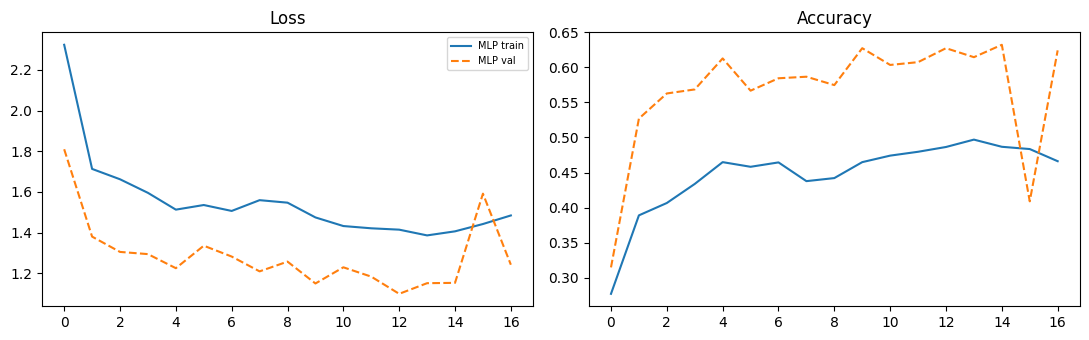

                           0
Modèle              MLP (PV)
F1_macro_PV            0.508
Rappel_macro_PV        0.572
Precision_macro_PV     0.534
Accuracy_PV            0.615
Maladie_ratee_PV       0.047
F1_macro_PD            0.059
Rappel_macro_PD        0.091
Precision_macro_PD     0.047
Accuracy_PD            0.087
Maladie_ratee_PD       0.213


In [7]:
mlp = fit(build_mlp(), X_pv_tr, y_pv_tr, X_pv_va, y_pv_va, "MLP")
plot_history(["MLP"]); evaluate(mlp, "MLP (PV)")

## 6. CNN from scratch : comparaison de variantes
- A : 3 blocs, sans batch normalization
- B : 3 blocs, avec batch normalization
- C : 2 blocs, avec batch normalization (moins profond)


===== CNN-A (sans BN)
Epoch 1/20
165/165 - 25s - 154ms/step - accuracy: 0.2501 - loss: 1.9910 - val_accuracy: 0.4013 - val_loss: 1.6558
Epoch 2/20
165/165 - 2s - 12ms/step - accuracy: 0.5037 - loss: 1.5830 - val_accuracy: 0.7013 - val_loss: 0.9953
Epoch 3/20
165/165 - 2s - 12ms/step - accuracy: 0.5940 - loss: 1.2559 - val_accuracy: 0.6920 - val_loss: 0.9063
Epoch 4/20
165/165 - 2s - 13ms/step - accuracy: 0.6572 - loss: 1.0465 - val_accuracy: 0.7677 - val_loss: 0.6487
Epoch 5/20
165/165 - 2s - 13ms/step - accuracy: 0.6851 - loss: 0.9683 - val_accuracy: 0.8027 - val_loss: 0.5721
Epoch 6/20
165/165 - 2s - 13ms/step - accuracy: 0.6959 - loss: 0.8977 - val_accuracy: 0.7712 - val_loss: 0.6320
Epoch 7/20
165/165 - 2s - 11ms/step - accuracy: 0.7234 - loss: 0.8343 - val_accuracy: 0.7965 - val_loss: 0.6220
Epoch 8/20
165/165 - 2s - 12ms/step - accuracy: 0.7477 - loss: 0.7600 - val_accuracy: 0.8398 - val_loss: 0.5064
Epoch 9/20
165/165 - 2s - 12ms/step - accuracy: 0.7582 - loss: 0.7307 - val_acc

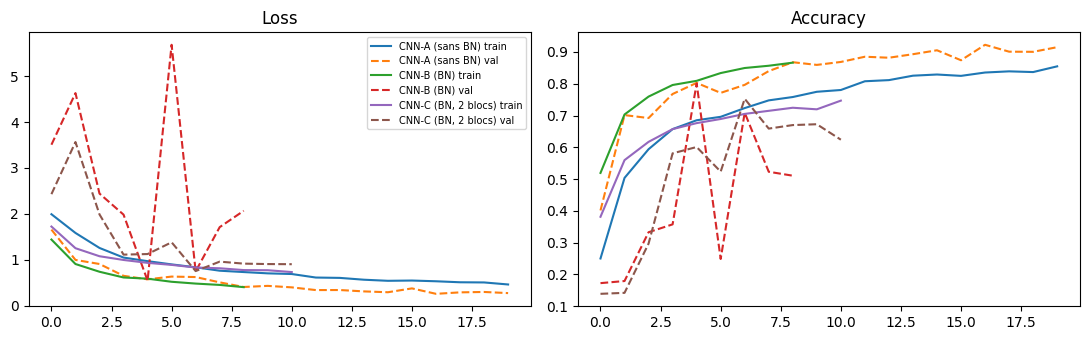

In [8]:
variants = {"CNN-A (sans BN)": dict(bn=False), "CNN-B (BN)": dict(bn=True), "CNN-C (BN, 2 blocs)": dict(bn=True, filters=(32, 64))}
CNN = {}
for n, kw in variants.items():
    print("\n=====", n)
    CNN[n] = fit(build_cnn(name=n.split()[0], **kw), X_pv_tr, y_pv_tr, X_pv_va, y_pv_va, n)
    evaluate(CNN[n], n)
plot_history(list(variants))

In [9]:
# Meilleur CNN de base choisi sur la VALIDATION PlantVillage (pas sur PlantDoc)
val_f1 = {n: f1_score(y_pv_va, predict(m, X_pv_va), average="macro") for n, m in CNN.items()}
BEST = max(val_f1, key=val_f1.get); BEST_KW = variants[BEST]
print("F1 macro validation :", {k: round(v, 3) for k, v in val_f1.items()}, "->", BEST)
base_model = CNN[BEST]

F1 macro validation : {'CNN-A (sans BN)': 0.903, 'CNN-B (BN)': 0.749, 'CNN-C (BN, 2 blocs)': 0.685} -> CNN-A (sans BN)


## 7. Test de robustesse : PlantVillage -> PlantDoc
La chute de performance se lit en comparant les colonnes `_PV` et `_PD` du tableau de résultats.

In [10]:
print("Chute de performance du modèle", BEST)
res = pd.DataFrame(ROWS).set_index("Modèle")
display(res.loc[[BEST], ["F1_macro_PV", "F1_macro_PD", "Rappel_macro_PV", "Rappel_macro_PD", "Maladie_ratee_PV", "Maladie_ratee_PD"]])

Chute de performance du modèle CNN-A (sans BN)


,F1_macro_PV,F1_macro_PD,Rappel_macro_PV,Rappel_macro_PD,Maladie_ratee_PV,Maladie_ratee_PD
Modèle,,,,,,
CNN-A (sans BN),0.872,0.167,0.892,0.229,0.003,0.0


### 7.1 Data augmentation (rotations, luminosité, contraste, zoom)

In [11]:
m_aug = fit(build_cnn(augment=True, name="aug", **BEST_KW), X_pv_tr, y_pv_tr, X_pv_va, y_pv_va, "S1 Augmentation", epochs=30)
evaluate(m_aug, "S1 Augmentation (PV)")

Epoch 1/30
165/165 - 11s - 67ms/step - accuracy: 0.1873 - loss: 2.0356 - val_accuracy: 0.3867 - val_loss: 1.7375
Epoch 2/30
165/165 - 2s - 14ms/step - accuracy: 0.4464 - loss: 1.6868 - val_accuracy: 0.5150 - val_loss: 1.4152
Epoch 3/30
165/165 - 2s - 15ms/step - accuracy: 0.5067 - loss: 1.4999 - val_accuracy: 0.5805 - val_loss: 1.2482
Epoch 4/30
165/165 - 2s - 14ms/step - accuracy: 0.5590 - loss: 1.3391 - val_accuracy: 0.6637 - val_loss: 0.9799
Epoch 5/30
165/165 - 2s - 15ms/step - accuracy: 0.5818 - loss: 1.2453 - val_accuracy: 0.5903 - val_loss: 1.1424
Epoch 6/30
165/165 - 3s - 18ms/step - accuracy: 0.6098 - loss: 1.1292 - val_accuracy: 0.7128 - val_loss: 0.8332
Epoch 7/30
165/165 - 2s - 15ms/step - accuracy: 0.6126 - loss: 1.0980 - val_accuracy: 0.7217 - val_loss: 0.8397
Epoch 8/30
165/165 - 2s - 15ms/step - accuracy: 0.6313 - loss: 1.0139 - val_accuracy: 0.7367 - val_loss: 0.7810
Epoch 9/30
165/165 - 2s - 14ms/step - accuracy: 0.6615 - loss: 0.9313 - val_accuracy: 0.7925 - val_loss

### 7.2 Augmentation + changement de fond
Les pixels peu saturés (fond gris/blanc de PlantVillage) sont remplacés par des images de fond issues de PlantDoc **train** uniquement (jamais du test). C'est une approximation : à discuter dans le rapport.

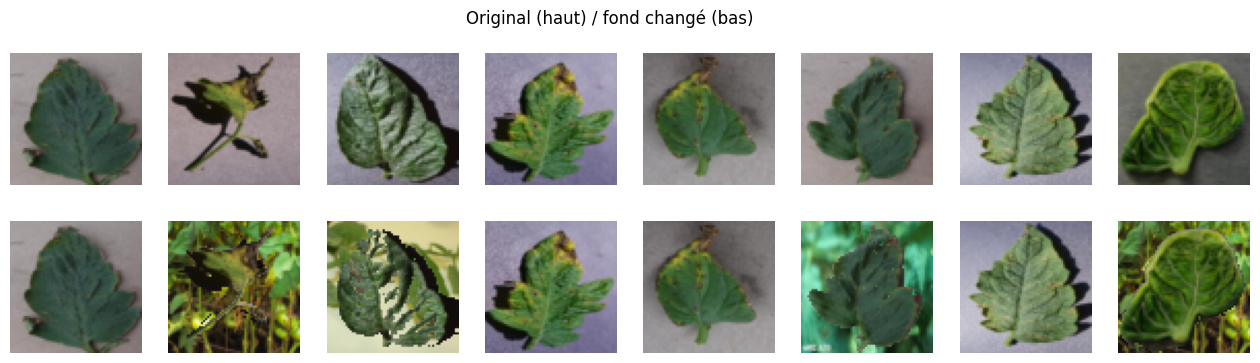

Epoch 1/30
165/165 - 5s - 28ms/step - accuracy: 0.2043 - loss: 2.0693 - val_accuracy: 0.4075 - val_loss: 1.8336
Epoch 2/30
165/165 - 2s - 14ms/step - accuracy: 0.2791 - loss: 2.0250 - val_accuracy: 0.3257 - val_loss: 1.8577
Epoch 3/30
165/165 - 3s - 19ms/step - accuracy: 0.3064 - loss: 1.9683 - val_accuracy: 0.3956 - val_loss: 1.7471
Epoch 4/30
165/165 - 2s - 15ms/step - accuracy: 0.3601 - loss: 1.8444 - val_accuracy: 0.4257 - val_loss: 1.6362
Epoch 5/30
165/165 - 2s - 13ms/step - accuracy: 0.3857 - loss: 1.7760 - val_accuracy: 0.4655 - val_loss: 1.4841
Epoch 6/30
165/165 - 2s - 15ms/step - accuracy: 0.4057 - loss: 1.7210 - val_accuracy: 0.5137 - val_loss: 1.4064
Epoch 7/30
165/165 - 2s - 15ms/step - accuracy: 0.4153 - loss: 1.6793 - val_accuracy: 0.5447 - val_loss: 1.3552
Epoch 8/30
165/165 - 3s - 17ms/step - accuracy: 0.4502 - loss: 1.6181 - val_accuracy: 0.5858 - val_loss: 1.2156
Epoch 9/30
165/165 - 3s - 16ms/step - accuracy: 0.4627 - loss: 1.5849 - val_accuracy: 0.5779 - val_loss:

In [12]:
def swap_background(X, bg_pool, p=0.7, sat_thr=0.18, seed=SEED):
    rng = np.random.default_rng(seed); out = X.copy()
    for s in range(0, len(X), 1000):
        mask = rgb_to_hsv(X[s:s + 1000] / 255.0)[..., 1] < sat_thr
        for k in range(len(mask)):
            if rng.random() < p:
                bg = bg_pool[rng.integers(len(bg_pool))]
                if rng.random() < 0.5: bg = bg[:, ::-1]
                out[s + k] = np.where(mask[k][..., None], bg, X[s + k])
    return out

X_pv_tr_bg = swap_background(X_pv_tr, X_pd_tr)
fig, ax = plt.subplots(2, 8, figsize=(16, 4))
for j in range(8):
    ax[0, j].imshow(X_pv_tr[j]); ax[1, j].imshow(X_pv_tr_bg[j]); ax[0, j].axis("off"); ax[1, j].axis("off")
plt.suptitle("Original (haut) / fond changé (bas)"); plt.show()

m_aug_bg = fit(build_cnn(augment=True, name="aug_bg", **BEST_KW), X_pv_tr_bg, y_pv_tr, X_pv_va, y_pv_va, "S2 Aug + fond", epochs=30)
evaluate(m_aug_bg, "S2 Aug + fond (PV)")

### 7.3 Ré-entraînement (fine-tuning) sur une partie de PlantDoc
On repart du modèle S2 et on l'entraîne sur PlantDoc train (learning rate faible), validation sur PlantDoc val.

In [13]:
import copy
m_ft = models.clone_model(m_aug_bg); m_ft.set_weights(m_aug_bg.get_weights())
m_ft = fit(m_ft, X_pd_tr, y_pd_tr, X_pd_va, y_pd_va, "S3 Fine-tuning PD", epochs=30, lr=1e-4, patience=6)
evaluate(m_ft, "S3 Fine-tuning PD")

Epoch 1/30
9/9 - 3s - 337ms/step - accuracy: 0.2167 - loss: 2.4794 - val_accuracy: 0.2222 - val_loss: 2.3616
Epoch 2/30
9/9 - 0s - 20ms/step - accuracy: 0.2074 - loss: 2.3979 - val_accuracy: 0.2148 - val_loss: 2.2461
Epoch 3/30
9/9 - 0s - 19ms/step - accuracy: 0.2130 - loss: 2.2900 - val_accuracy: 0.2148 - val_loss: 2.1925
Epoch 4/30
9/9 - 0s - 20ms/step - accuracy: 0.2093 - loss: 2.1872 - val_accuracy: 0.2222 - val_loss: 2.1550
Epoch 5/30
9/9 - 0s - 19ms/step - accuracy: 0.2074 - loss: 2.2071 - val_accuracy: 0.2222 - val_loss: 2.1294
Epoch 6/30
9/9 - 0s - 25ms/step - accuracy: 0.2167 - loss: 2.1607 - val_accuracy: 0.2148 - val_loss: 2.1132
Epoch 7/30
9/9 - 0s - 33ms/step - accuracy: 0.2315 - loss: 2.1683 - val_accuracy: 0.2222 - val_loss: 2.0965
Epoch 8/30
9/9 - 0s - 27ms/step - accuracy: 0.2426 - loss: 2.0892 - val_accuracy: 0.2222 - val_loss: 2.0881
Epoch 9/30
9/9 - 0s - 37ms/step - accuracy: 0.2185 - loss: 2.1008 - val_accuracy: 0.2222 - val_loss: 2.0713
Epoch 10/30
9/9 - 0s - 29ms

### 7.4 Entraînement mixte PlantVillage + PlantDoc
PlantDoc est sur-échantillonné (x5) car il est bien plus petit.

Epoch 1/30
207/207 - 6s - 28ms/step - accuracy: 0.2259 - loss: 2.0730 - val_accuracy: 0.1850 - val_loss: 2.0601
Epoch 2/30
207/207 - 3s - 14ms/step - accuracy: 0.2243 - loss: 2.0365 - val_accuracy: 0.2251 - val_loss: 2.0315
Epoch 3/30
207/207 - 3s - 16ms/step - accuracy: 0.2559 - loss: 2.0062 - val_accuracy: 0.2752 - val_loss: 1.9442
Epoch 4/30
207/207 - 5s - 23ms/step - accuracy: 0.2750 - loss: 1.9712 - val_accuracy: 0.2739 - val_loss: 1.9115
Epoch 5/30
207/207 - 3s - 14ms/step - accuracy: 0.3184 - loss: 1.9160 - val_accuracy: 0.2868 - val_loss: 1.8134
Epoch 6/30
207/207 - 3s - 14ms/step - accuracy: 0.3588 - loss: 1.8240 - val_accuracy: 0.4505 - val_loss: 1.5996
Epoch 7/30
207/207 - 3s - 17ms/step - accuracy: 0.4026 - loss: 1.7387 - val_accuracy: 0.5436 - val_loss: 1.3673
Epoch 8/30
207/207 - 3s - 14ms/step - accuracy: 0.4299 - loss: 1.6998 - val_accuracy: 0.5261 - val_loss: 1.3382
Epoch 9/30
207/207 - 3s - 14ms/step - accuracy: 0.4454 - loss: 1.6524 - val_accuracy: 0.5850 - val_loss:

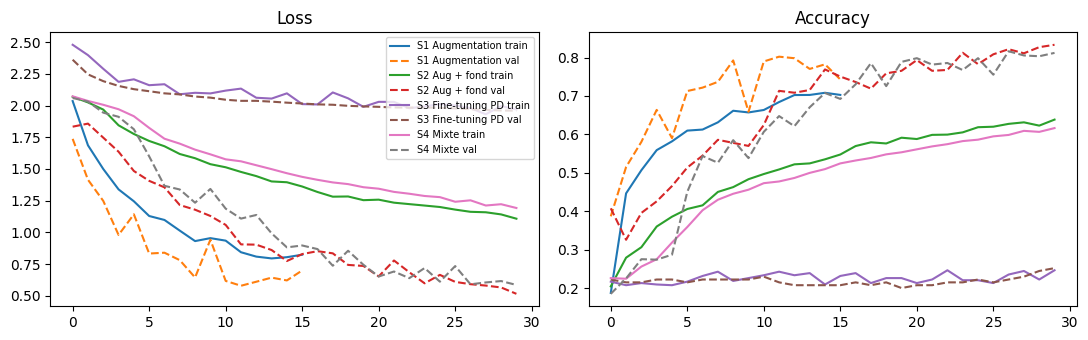

In [14]:
R = 5
X_mix = np.concatenate([X_pv_tr_bg] + [X_pd_tr] * R); y_mix = np.concatenate([y_pv_tr] + [y_pd_tr] * R)
X_mix_va = np.concatenate([X_pv_va, X_pd_va]);        y_mix_va = np.concatenate([y_pv_va, y_pd_va])
m_mix = fit(build_cnn(augment=True, name="mix", **BEST_KW), X_mix, y_mix, X_mix_va, y_mix_va, "S4 Mixte", epochs=30)
evaluate(m_mix, "S4 Entraînement mixte")
plot_history(["S1 Augmentation", "S2 Aug + fond", "S3 Fine-tuning PD", "S4 Mixte"])

## 8. Tableau de synthèse (laboratoire ET terrain)
Métrique principale : **F1 macro** et **rappel macro** sur PlantDoc ; `Maladie_ratee` = part des feuilles malades classées "saines" (l'erreur la plus coûteuse pour l'agriculteur).

,F1_macro_PV,Rappel_macro_PV,Precision_macro_PV,Accuracy_PV,Maladie_ratee_PV,F1_macro_PD,Rappel_macro_PD,Precision_macro_PD,Accuracy_PD,Maladie_ratee_PD
Modèle,,,,,,,,,,
MLP (PV),0.508,0.572,0.534,0.615,0.047,0.059,0.091,0.047,0.087,0.213
CNN-A (sans BN),0.872,0.892,0.860,0.900,0.003,0.167,0.229,0.238,0.217,0.000
CNN-B (BN),0.730,0.734,0.782,0.777,0.001,0.154,0.248,0.150,0.232,0.000
"CNN-C (BN, 2 blocs)",0.673,0.698,0.714,0.740,0.000,0.183,0.254,0.158,0.261,0.000
S1 Augmentation (PV),0.720,0.743,0.737,0.760,0.029,0.112,0.190,0.088,0.174,0.000
S2 Aug + fond (PV),0.767,0.785,0.768,0.822,0.046,0.228,0.264,0.214,0.261,0.115
S3 Fine-tuning PD,0.647,0.663,0.700,0.718,0.020,0.310,0.304,0.339,0.290,0.049
S4 Entraînement mixte,0.784,0.819,0.778,0.836,0.025,0.267,0.320,0.238,0.348,0.066


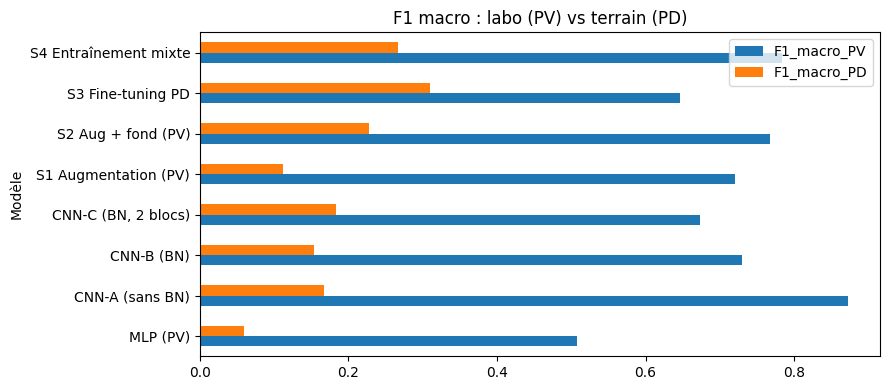

In [15]:
RES = pd.DataFrame(ROWS).set_index("Modèle")
display(RES)
RES[["F1_macro_PV", "F1_macro_PD"]].plot.barh(figsize=(9, 4), title="F1 macro : labo (PV) vs terrain (PD)"); plt.tight_layout(); plt.show()
RES.to_csv("resultats.csv")

## 9. Analyse des erreurs
Choisissez le meilleur modèle selon la **validation PlantDoc** (pas le test).

Modèle final : S3 Fine-tuning PD
                   precision    recall  f1-score   support

   bacterial_spot       0.33      0.11      0.17         9
     early_blight       0.29      0.22      0.25         9
          healthy       0.57      0.50      0.53         8
      late_blight       0.14      0.30      0.19        10
        leaf_mold       0.33      0.33      0.33         6
     mosaic_virus       0.11      0.10      0.11        10
         septoria       0.44      0.36      0.40        11
yellow_curl_virus       0.50      0.50      0.50         6

         accuracy                           0.29        69
        macro avg       0.34      0.30      0.31        69
     weighted avg       0.33      0.29      0.29        69



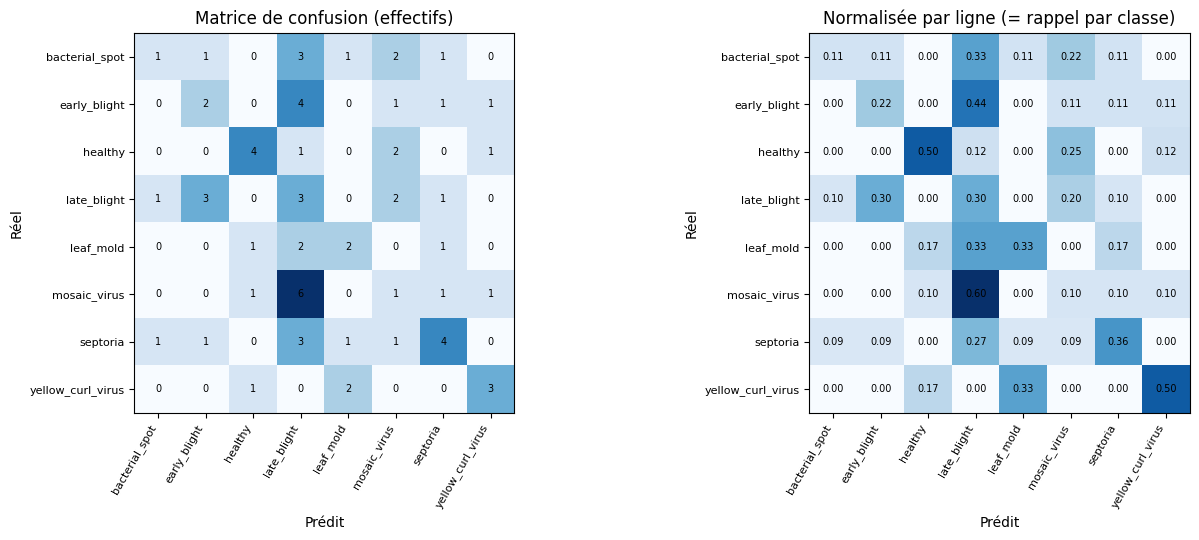

In [16]:
cands = {"S2 Aug + fond": m_aug_bg, "S3 Fine-tuning PD": m_ft, "S4 Mixte": m_mix}
FINAL_NAME = max(cands, key=lambda n: f1_score(y_pd_va, predict(cands[n], X_pd_va), average="macro"))
final = cands[FINAL_NAME]; print("Modèle final :", FINAL_NAME)

p_te = predict(final, X_pdte)
print(classification_report(y_pdte, p_te, labels=list(range(N)), target_names=CLASSES, zero_division=0))

cm = confusion_matrix(y_pdte, p_te, labels=list(range(N)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, M, t, f in [(ax[0], cm, "Matrice de confusion (effectifs)", "d"), (ax[1], cmn, "Normalisée par ligne (= rappel par classe)", ".2f")]:
    a.imshow(M, cmap="Blues"); a.set_xticks(range(N)); a.set_yticks(range(N))
    a.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8); a.set_yticklabels(CLASSES, fontsize=8)
    a.set_xlabel("Prédit"); a.set_ylabel("Réel"); a.set_title(t)
    for i in range(N):
        for j in range(N): a.text(j, i, format(M[i, j], f), ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.show()

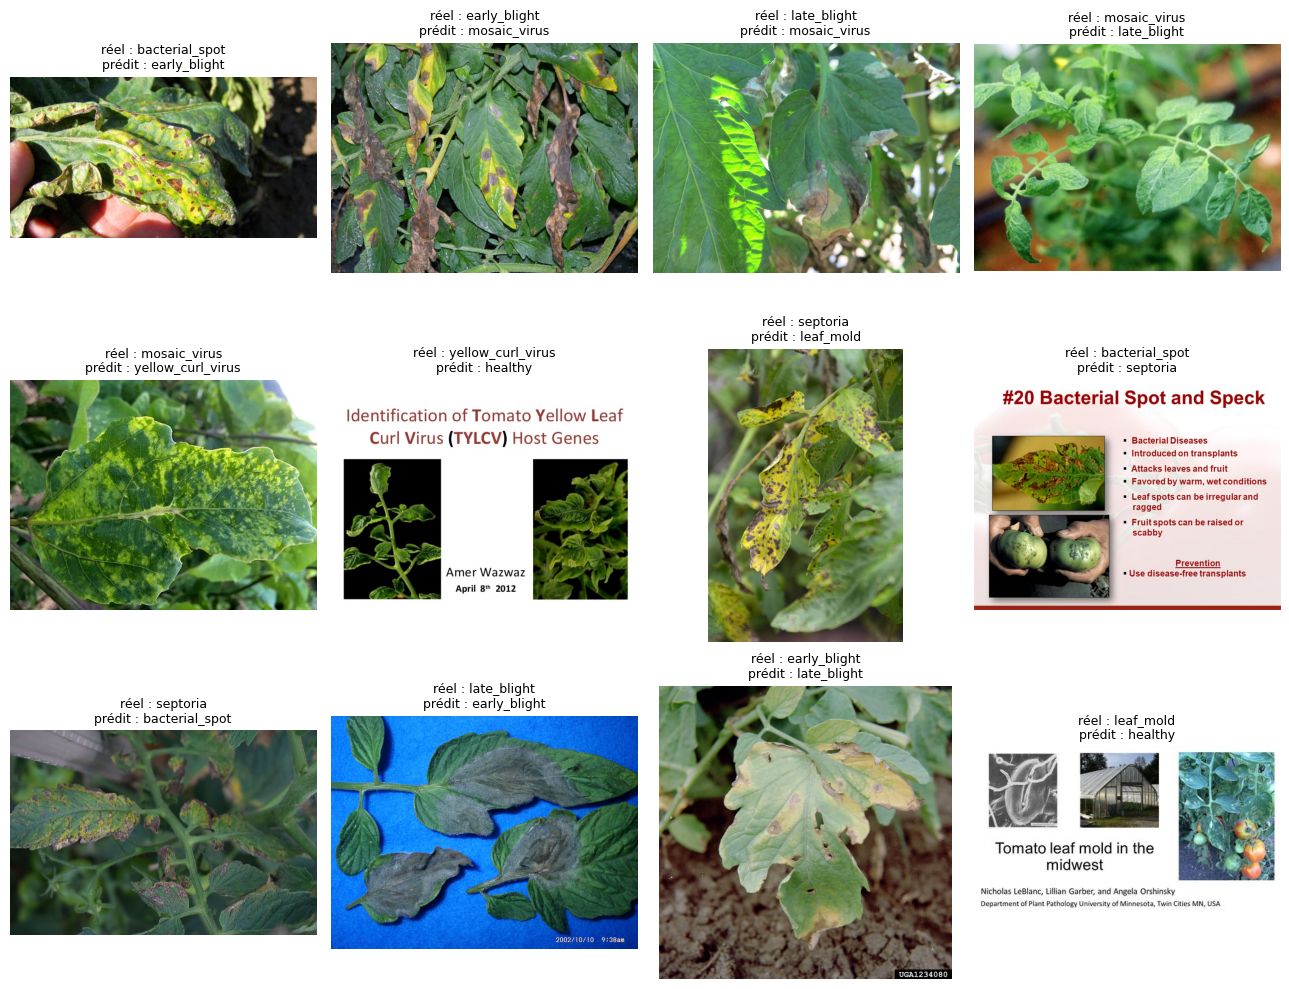

Hypothèses fréquentes à tester : fond chargé, feuille partielle, lumière forte/ombre, symptômes proches (early vs late blight, septoria), mauvais étiquetage, peu d'exemples de la classe.


In [17]:
# Exemples mal classés (images en meilleure résolution) : écrivez une hypothèse de cause par image dans le rapport
wrong = np.where(p_te != y_pdte)[0]
sel = np.random.default_rng(SEED).choice(wrong, size=min(12, len(wrong)), replace=False)
fig, ax = plt.subplots(3, 4, figsize=(13, 10))
for a, k in zip(ax.ravel(), sel):
    a.imshow(Image.open(p_pdte[k]).convert("RGB")); a.axis("off")
    a.set_title(f"réel : {CLASSES[y_pdte[k]]}\nprédit : {CLASSES[p_te[k]]}", fontsize=9)
plt.tight_layout(); plt.show()
print("Hypothèses fréquentes à tester : fond chargé, feuille partielle, lumière forte/ombre, symptômes proches (early vs late blight, septoria), mauvais étiquetage, peu d'exemples de la classe.")

## 10. Grad-CAM : le modèle regarde-t-il la lésion ou le fond ?

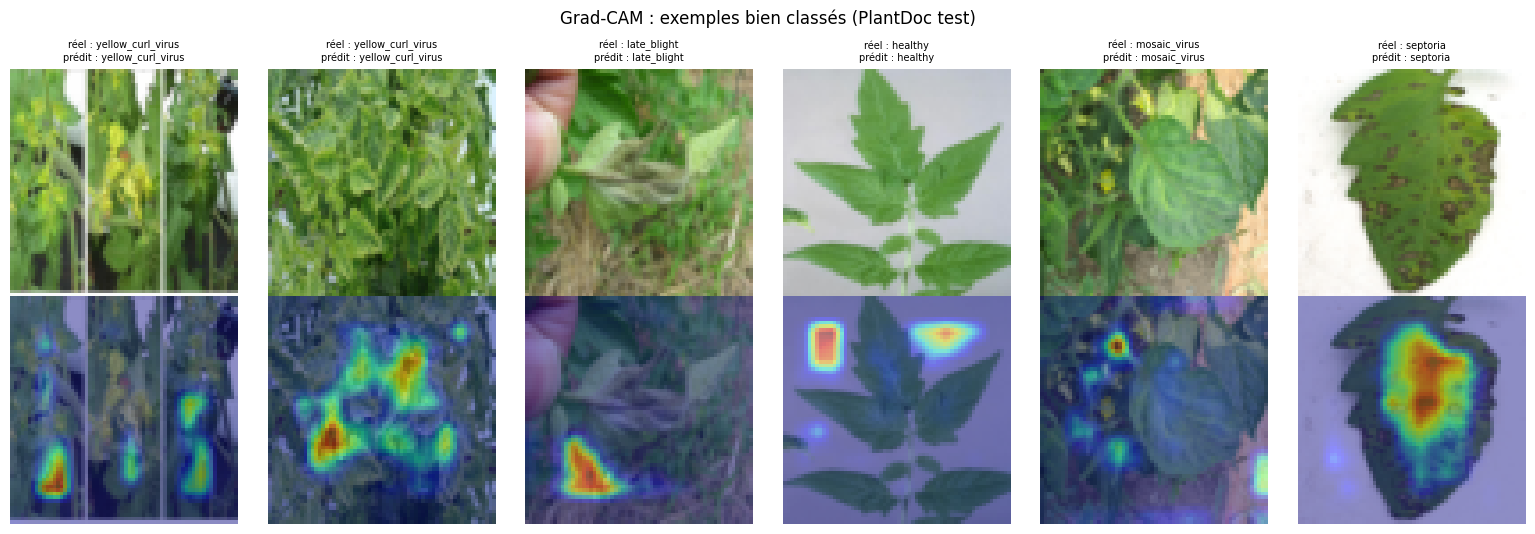

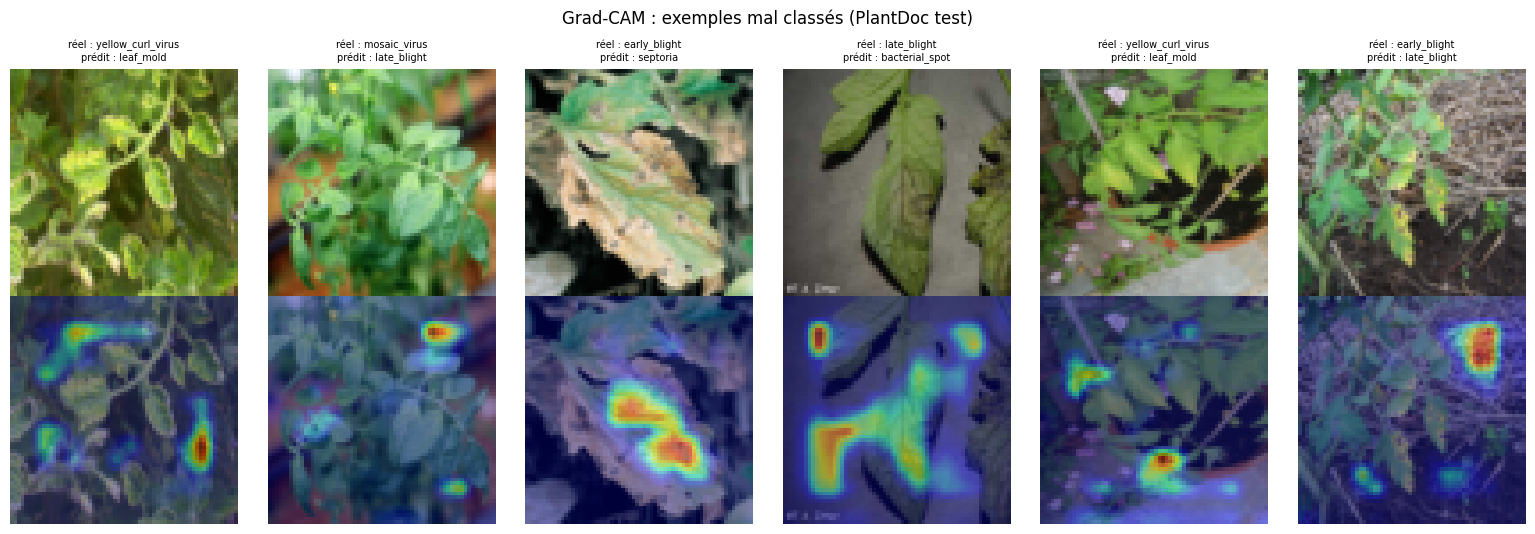

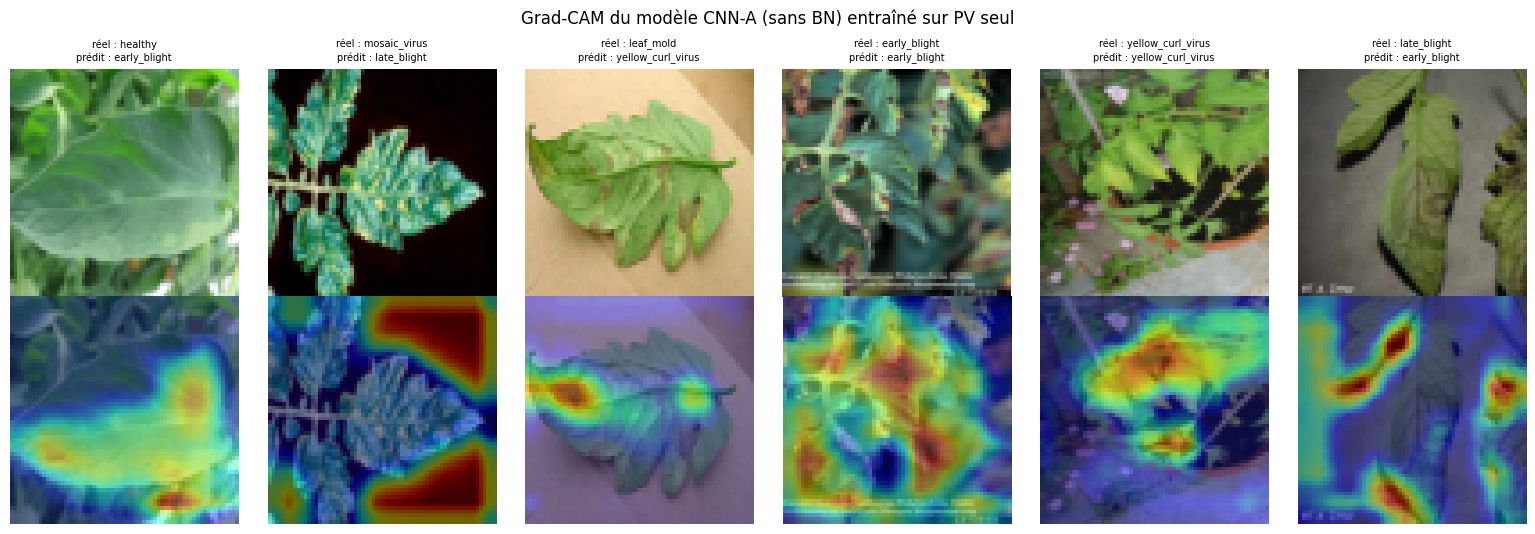

In [18]:
def gradcam(model, img, cls=None):
    gm = tf.keras.Model(model.inputs, [model.get_layer("last_conv").output, model.output])
    x = tf.cast(img[None], tf.float32)
    with tf.GradientTape() as tape:
        conv, pred = gm(x, training=False)
        c = int(tf.argmax(pred[0])) if cls is None else cls
        score = pred[:, c]
    g = tape.gradient(score, conv)
    w = tf.reduce_mean(g, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0].numpy()
    return cam / (cam.max() + 1e-8), c

def show_cams(idx, title):
    fig, ax = plt.subplots(2, len(idx), figsize=(2.6 * len(idx), 5.4))
    for j, k in enumerate(idx):
        cam, c = gradcam(final, X_pdte[k])
        ax[0, j].imshow(X_pdte[k]); ax[0, j].axis("off")
        ax[0, j].set_title(f"réel : {CLASSES[y_pdte[k]]}\nprédit : {CLASSES[c]}", fontsize=7)
        ax[1, j].imshow(X_pdte[k]); ax[1, j].imshow(tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0],
                                                   cmap="jet", alpha=0.45); ax[1, j].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
ok = np.where(p_te == y_pdte)[0]
show_cams(rng.choice(ok, size=min(6, len(ok)), replace=False), "Grad-CAM : exemples bien classés (PlantDoc test)")
show_cams(rng.choice(wrong, size=min(6, len(wrong)), replace=False), "Grad-CAM : exemples mal classés (PlantDoc test)")

# Comparaison : modèle PV seul (sans augmentation) vs modèle final sur les mêmes images
final_backup = final
final = base_model
show_cams(rng.choice(len(X_pdte), size=6, replace=False), f"Grad-CAM du modèle {BEST} entraîné sur PV seul")
final = final_backup

## 11. À copier dans le rapport
- Tableau de la section 8 (laboratoire ET terrain), avec la chute PV -> PD du modèle de base.
- Effet de chaque stratégie (S1 à S4) sur F1 macro, rappel et `Maladie_ratee` (PlantDoc).
- Matrice de confusion, rappel par classe, exemples mal classés avec une hypothèse chacun.
- Grad-CAM : fond ou lésion ?
- Limites : petit jeu PlantDoc, résolution 64x64, fuite possible dans PlantVillage (plusieurs photos par feuille), changement de fond approximatif, une seule graine, pas de test sur de vraies photos de smartphone d'agriculteurs.